# Rethinking generalization — Small Inception on CIFAR-10

Replicates Figure 1a of Zhang et al. (2017): training loss vs. epochs for true labels and
five corrupted versions of CIFAR-10. Same hyperparameters for every condition.

In [1]:
import time, json, math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

device: cuda Tesla T4


## Data

In [2]:
!pip install datasets -q

In [3]:
from datasets import load_dataset

# trust_remote_code removed: this dataset is plain Parquet now, and the flag is deprecated
hf_dataset = load_dataset("uoft-cs/cifar10")

def to_numpy(split):
    """Decode every PIL image ONCE -> uint8 array (N, 32, 32, 3) and int labels (N,)."""
    imgs = np.stack([np.asarray(im) for im in split["img"]])
    labels = np.asarray(split["label"], dtype=np.int64)
    return imgs, labels

train_imgs, train_labels = to_numpy(hf_dataset["train"])
test_imgs,  test_labels  = to_numpy(hf_dataset["test"])
print(train_imgs.shape, train_labels.shape, test_imgs.shape, test_labels.shape)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

(50000, 32, 32, 3) (50000,) (10000, 32, 32, 3) (10000,)


## Preprocessing

> We divide the pixel values by 255 to scale them into [0, 1], crop from the center to get 28x28
> inputs, and then normalize them by subtracting the mean and dividing the adjusted standard
> deviation independently for each image with the per_image_whitening function in TensorFlow.

Because the paper uses **no data augmentation**, every image is identical every epoch. So we
preprocess the whole dataset **once** into a tensor instead of re-running a PIL transform per
image per epoch (that was the bottleneck: ~31 s/epoch spent mostly decoding images on the CPU).

Order matters: **scale + crop → corruption → whitening.** The corruptions are defined on the
images themselves, and whitening is the last step of the input pipeline.

In [4]:
def scale_and_crop(imgs_uint8):
    """(N, 32, 32, 3) uint8 -> (N, 3, 28, 28) float32 in [0, 1], center-cropped."""
    x = torch.from_numpy(imgs_uint8).permute(0, 3, 1, 2).float() / 255.0
    return x[:, :, 2:30, 2:30].contiguous()       # (32 - 28) / 2 = 2 pixels off each side

def per_image_whitening(x):
    """Batched TF per_image_whitening: each image uses its OWN mean/std over all C*H*W values.
       x' = (x - mean) / max(std, 1/sqrt(N)),  N = C*H*W."""
    n = x[0].numel()
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    std = x.std(dim=(1, 2, 3), keepdim=True, unbiased=False)
    return (x - mean) / torch.clamp(std, min=1.0 / math.sqrt(n))

base_train_x = scale_and_crop(train_imgs)   # kept on CPU; each condition starts from these
base_test_x  = scale_and_crop(test_imgs)
base_train_y = torch.from_numpy(train_labels)
base_test_y  = torch.from_numpy(test_labels)
print(base_train_x.shape, base_train_x.min().item(), base_train_x.max().item())

torch.Size([50000, 3, 28, 28]) 0.0 1.0


## Corruptions

Definitions from Section 2 of the paper:

| Condition | What changes | Applied to |
|---|---|---|
| **True labels** | nothing | — |
| **Random labels** | every label replaced by a uniform random class (`corrupt_labels` with p = 1; any p in [0, 1] gives the partially-corrupted setting) | train labels |
| **Shuffled pixels** | ONE random permutation of the 784 pixel positions, applied to every image | train **and** test images |
| **Random pixels** | a DIFFERENT random permutation for each image | train and test images |
| **Gaussian** | every image replaced by Gaussian noise with the dataset's per-channel mean and variance | train and test images |

A pixel permutation moves (R, G, B) triples together: it rearranges *where* pixels are,
not the colors themselves. Test labels are never corrupted.

Every corruption is generated once, with a fixed seed, before training. The labels must stay
**consistent across epochs**; re-randomizing each epoch would be a different (and unlearnable)
experiment.

In [5]:
# ---- label corruptions -------------------------------------------------------------
def corrupt_labels(y, p, gen, num_classes=10):
    """Independently with probability p, replace each label by a uniform random class."""
    y = y.clone()
    mask = torch.rand(len(y), generator=gen) < p
    y[mask] = torch.randint(0, num_classes, (int(mask.sum()),), generator=gen)
    return y

def shuffle_labels(y, gen):
    """Permute the existing labels across images."""
    return y[torch.randperm(len(y), generator=gen)]

# ---- input corruptions -------------------------------------------------------------
def permute_pixels(x, perm):
    """Apply one permutation of the H*W pixel positions to every image."""
    N, C, H, W = x.shape
    return x.reshape(N, C, H * W)[:, :, perm].reshape(N, C, H, W)

def random_permute_pixels(x, gen, chunk=5000):
    """Apply an independent random permutation of pixel positions to each image."""
    N, C, H, W = x.shape
    out = torch.empty_like(x)
    flat = x.reshape(N, C, H * W)
    for s in range(0, N, chunk):
        e = min(s + chunk, N)
        perms = torch.argsort(torch.rand(e - s, H * W, generator=gen), dim=1)   # one perm per row
        idx = perms.unsqueeze(1).expand(-1, C, -1)                              # same perm for R, G, B
        out[s:e] = flat[s:e].gather(2, idx).reshape(e - s, C, H, W)
    return out

def gaussian_images(shape, mean_c, std_c, gen):
    """Pure noise images: pixel ~ N(mean_c, std_c^2) independently, per channel c."""
    z = torch.randn(shape, generator=gen)
    return z * std_c.view(1, -1, 1, 1) + mean_c.view(1, -1, 1, 1)

# per-channel statistics of the (scaled, cropped) training images, for the Gaussian condition
CH_MEAN = base_train_x.mean(dim=(0, 2, 3))
CH_STD  = base_train_x.std(dim=(0, 2, 3))

# ---- build one condition -------------------------------------------------------------
# The five conditions in the paper's Figure 1a.
CONDITIONS = ["true_labels", "random_labels", "shuffled_pixels", "random_pixels", "gaussian"]
# Extra condition, not in the paper. Uncomment to add it to the plot:
# CONDITIONS.append("shuffled_labels")

def make_condition(name, seed=SEED):
    """Returns whitened (Xtr, Ytr, Xte, Yte) on the device for the named condition."""
    gen = torch.Generator().manual_seed(seed)
    Xtr, Ytr = base_train_x, base_train_y
    Xte, Yte = base_test_x,  base_test_y
    HW = Xtr.shape[2] * Xtr.shape[3]

    if name == "true_labels":
        pass
    elif name == "random_labels":
        Ytr = corrupt_labels(Ytr, p=1.0, gen=gen)
    elif name == "shuffled_labels":
        Ytr = shuffle_labels(Ytr, gen)
    elif name == "shuffled_pixels":
        perm = torch.randperm(HW, generator=gen)          # ONE permutation, shared by train and test
        Xtr, Xte = permute_pixels(Xtr, perm), permute_pixels(Xte, perm)
    elif name == "random_pixels":
        Xtr, Xte = random_permute_pixels(Xtr, gen), random_permute_pixels(Xte, gen)
    elif name == "gaussian":
        Xtr = gaussian_images(Xtr.shape, CH_MEAN, CH_STD, gen)
        Xte = gaussian_images(Xte.shape, CH_MEAN, CH_STD, gen)
    else:
        raise ValueError(f"unknown condition {name!r}")

    return (per_image_whitening(Xtr).to(device), Ytr.to(device),
            per_image_whitening(Xte).to(device), Yte.to(device))

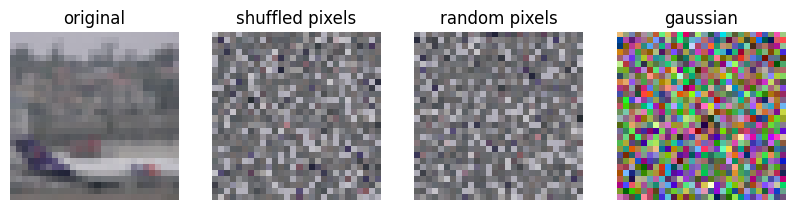

In [6]:
# Look at one image under each input corruption (before whitening, so colors are meaningful).
gen = torch.Generator().manual_seed(2)
img = base_train_x[:1]
views = {
    "original": img,
    "shuffled pixels": permute_pixels(img, torch.randperm(784, generator=gen)),
    "random pixels": random_permute_pixels(img, gen),
    "gaussian": gaussian_images(img.shape, CH_MEAN, CH_STD, gen).clamp(0, 1),
}
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, (title, v) in zip(axes, views.items()):
    ax.imshow(v[0].permute(1, 2, 0).numpy()); ax.set_title(title); ax.axis("off")
plt.show()

## Model

**BatchNorm as in TensorFlow.** PyTorch's BatchNorm learns a scale γ and a shift β per channel.
TensorFlow's `batch_norm` layer of that era defaulted to `scale=False`, which learns only β.
With `MATCH_TF_BATCHNORM = True`, the model uses shift-only BN, and the parameter count is
exactly the paper's 1,649,402.

Dropping γ costs nothing in expressiveness here. BN is followed by ReLU and then a conv.
ReLU is positively homogeneous: relu(γz) = γ·relu(z) for γ > 0. So the next layer's weights can
absorb any positive per-channel scale.

In [7]:
MATCH_TF_BATCHNORM = True

class ShiftOnlyBatchNorm2d(nn.Module):
    """BatchNorm with a learnable shift beta but no scale gamma (TF's scale=False)."""

    def __init__(self, ch):
        super().__init__()
        self.bn = nn.BatchNorm2d(ch, affine=False)        # normalization + running stats only
        self.beta = nn.Parameter(torch.zeros(ch))

    def forward(self, x):
        return self.bn(x) + self.beta.view(1, -1, 1, 1)


class ConvModule(nn.Module):
    """Conv(C, KxK, stride S) -> BatchNorm -> ReLU."""

    def __init__(self, in_ch, out_ch, kernel_size, stride, padding="same"):
        super().__init__()
        if padding == "same":
            padding = kernel_size // 2  # keeps H, W unchanged when stride = 1
        # bias=False: BatchNorm subtracts the per-channel mean right after,
        # which cancels any constant bias, so BN's own shift (beta) replaces it.
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding, bias=False)
        self.bn = ShiftOnlyBatchNorm2d(out_ch) if MATCH_TF_BATCHNORM else nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))


class InceptionModule(nn.Module):
    """ConvModule(ch1, 1x1, s=1) || ConvModule(ch3, 3x3, s=1), concatenated in channels."""

    def __init__(self, in_ch, ch1, ch3):
        super().__init__()
        self.branch1 = ConvModule(in_ch, ch1, kernel_size=1, stride=1)
        self.branch3 = ConvModule(in_ch, ch3, kernel_size=3, stride=1)
        self.out_ch = ch1 + ch3

    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch3(x)], dim=1)


class DownsampleModule(nn.Module):
    """ConvModule(ch3, 3x3, s=2) || MaxPool(3x3, s=2), concatenated in channels.
       padding=1 on both, so H, W -> H/2 (28 -> 14 -> 7)."""

    def __init__(self, in_ch, ch3):
        super().__init__()
        self.conv = ConvModule(in_ch, ch3, kernel_size=3, stride=2, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.out_ch = ch3 + in_ch

    def forward(self, x):
        return torch.cat([self.conv(x), self.pool(x)], dim=1)


class SmallInception(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        layers = [ConvModule(3, 96, kernel_size=3, stride=1)]
        ch = 96

        def inc(c1, c3):
            nonlocal ch
            m = InceptionModule(ch, c1, c3); ch = m.out_ch; layers.append(m)

        def down(c3):
            nonlocal ch
            m = DownsampleModule(ch, c3); ch = m.out_ch; layers.append(m)

        inc(32, 32); inc(32, 48); down(80)                       # 28x28 -> 14x14
        inc(112, 48); inc(96, 64); inc(80, 80); inc(48, 96); down(96)   # 14x14 -> 7x7
        inc(176, 160); inc(176, 160)

        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)   # global 7x7 mean pooling
        self.fc = nn.Linear(ch, num_classes)

    def forward(self, x):
        x = self.features(x)
        return self.fc(torch.flatten(self.pool(x), 1))


print("params:", sum(p.numel() for p in SmallInception().parameters()), "  paper: 1649402")

params: 1649402   paper: 1649402


## Training

Paper setup: SGD, momentum 0.9, lr 0.1, decay ×0.95 per epoch, no weight decay / dropout,
batch size 128 (the paper doesn't state it; 128 is standard).

**Epoch count.** Figure 1a's x-axis runs to about 25,000 steps. At 391 steps per epoch that is
about **64 epochs**. Running 1,000 epochs does nothing useful: after epoch t the learning rate is
0.1 · 0.95ᵗ, so by epoch 200 it is about 3.5 × 10⁻⁶ and training has effectively stopped.

**Metric.** `average_loss` is the mean training loss over all batches in the epoch. The last
batch's loss alone is noisy: it is the loss on just 80 images (50,000 mod 128).

**Precision.** The paper trained in float32, so `USE_AMP = False` by default. Setting it to True
runs the convolutions in float16 on the GPU's tensor cores. That is roughly 2–3× faster on a T4/L4,
at the cost of a small departure from the paper's setup.

**Steps vs. epochs.** A *step* is one SGD update, i.e. one mini-batch. One epoch is
⌈50,000 / 128⌉ = 391 steps. The history records both, and the plots use thousand steps like the paper.

In [8]:
BATCH_SIZE = 128
NUM_EPOCHS = 64          # ≈ 25k steps, matching Figure 1a
LR, MOMENTUM, GAMMA = 0.1, 0.9, 0.95
USE_AMP = False          # paper used float32; True = faster float16 (needs a GPU)
USE_AMP = USE_AMP and device == "cuda"

@torch.no_grad()
def evaluate(model, X, Y, batch_size=1000):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(X[i:i + batch_size])
        correct += (logits.argmax(1) == Y[i:i + batch_size]).sum().item()
    return correct / len(X)

STEPS_PER_EPOCH = math.ceil(50000 / BATCH_SIZE)   # 391

def train_model(model_fn, data, lr, num_epochs, seed=SEED, converge_acc=None, tag="", verbose=True):
    """Generic training loop used by every figure.

    model_fn:      zero-argument function returning a fresh model
    data:          (Xtr, Ytr, Xte, Yte), already on the device
    converge_acc:  if set, stop at the first epoch whose training accuracy >= converge_acc
                   and record that as the convergence time (used for Figure 1b/1c)
    """
    Xtr, Ytr, Xte, Yte = data
    torch.manual_seed(seed)                       # same initialization for every run of a model
    model = model_fn().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=MOMENTUM)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=GAMMA)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    hist = {"tag": tag, "avg_loss": [], "train_acc_online": [], "test_acc": [], "lr": [],
            "steps": [], "converged_epoch": None, "converged_step": None}
    n = len(Xtr)
    for epoch in range(num_epochs):
        model.train()
        t0 = time.time()
        total_loss, total_correct = 0.0, 0
        perm = torch.randperm(n, device=device)   # reshuffle each epoch (shuffle=True)
        for i in range(0, n, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            x, y = Xtr[idx], Ytr[idx]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            # weight by batch size so the last, smaller batch counts correctly
            total_loss += loss.item() * len(idx)
            total_correct += (logits.argmax(1) == y).sum().item()
        hist["lr"].append(scheduler.get_last_lr()[0])   # lr USED this epoch
        scheduler.step()

        hist["avg_loss"].append(total_loss / n)
        hist["train_acc_online"].append(total_correct / n)
        hist["test_acc"].append(evaluate(model, Xte, Yte))
        hist["steps"].append((epoch + 1) * STEPS_PER_EPOCH)
        if verbose:
            print(f"[{tag}] epoch {epoch:3d}  lr {hist['lr'][-1]:.5f}  "
                  f"avg_loss {hist['avg_loss'][-1]:.4f}  train_acc {hist['train_acc_online'][-1]:.4f}  "
                  f"test_acc {hist['test_acc'][-1]:.4f}  ({time.time() - t0:.1f}s)")

        if converge_acc is not None and hist["train_acc_online"][-1] >= converge_acc:
            hist["converged_epoch"] = epoch + 1
            hist["converged_step"] = hist["steps"][-1]
            break

    # final training accuracy with the trained model in eval mode (BN running stats)
    hist["final_train_acc"] = evaluate(model, Xtr, Ytr)
    hist["final_test_acc"] = hist["test_acc"][-1]
    del model
    if device == "cuda":
        torch.cuda.empty_cache()
    return hist


def run_experiment(condition, num_epochs=NUM_EPOCHS, lr=LR, seed=SEED, verbose=True):
    """Figure 1a: Small Inception, fixed number of epochs, one corruption condition."""
    data = make_condition(condition, seed=seed)
    hist = train_model(SmallInception, data, lr, num_epochs, seed=seed, tag=condition, verbose=verbose)
    del data
    return hist

Optional: save results to Google Drive after every condition, so a Colab disconnect doesn't
cost you finished runs. Re-running the next cell skips any condition already saved.

In [ ]:
from google.colab import drive; drive.mount("/content/drive")
RESULTS_PATH = "/content/drive/MyDrive/rethinking_generalization_results.json"

try:
    with open(RESULTS_PATH) as f:
        results = json.load(f)
except FileNotFoundError:
    results = {}
print("already done:", list(results))

Mounted at /content/drive
already done: ['true_labels', 'random_labels']


In [ ]:
for cond in CONDITIONS:
    if cond in results:
        continue
    results[cond] = run_experiment(cond)
    with open(RESULTS_PATH, "w") as f:
        json.dump(results, f)

[shuffled_pixels] epoch   0  lr 0.10000  avg_loss 1.8678  train_acc 0.3086  test_acc 0.3468  (28.0s)
[shuffled_pixels] epoch   1  lr 0.09500  avg_loss 1.6055  train_acc 0.4169  test_acc 0.3532  (26.1s)
[shuffled_pixels] epoch   2  lr 0.09025  avg_loss 1.4616  train_acc 0.4744  test_acc 0.4462  (27.3s)
[shuffled_pixels] epoch   3  lr 0.08574  avg_loss 1.3486  train_acc 0.5163  test_acc 0.4837  (30.2s)
[shuffled_pixels] epoch   4  lr 0.08145  avg_loss 1.2496  train_acc 0.5500  test_acc 0.4708  (30.3s)
[shuffled_pixels] epoch   5  lr 0.07738  avg_loss 1.1566  train_acc 0.5836  test_acc 0.5040  (29.1s)
[shuffled_pixels] epoch   6  lr 0.07351  avg_loss 1.0619  train_acc 0.6185  test_acc 0.4805  (29.9s)
[shuffled_pixels] epoch   7  lr 0.06983  avg_loss 0.9672  train_acc 0.6527  test_acc 0.4843  (29.8s)
[shuffled_pixels] epoch   8  lr 0.06634  avg_loss 0.8709  train_acc 0.6844  test_acc 0.4762  (29.6s)
[shuffled_pixels] epoch   9  lr 0.06302  avg_loss 0.7729  train_acc 0.7203  test_acc 0.4060

## Results: Figure 1a

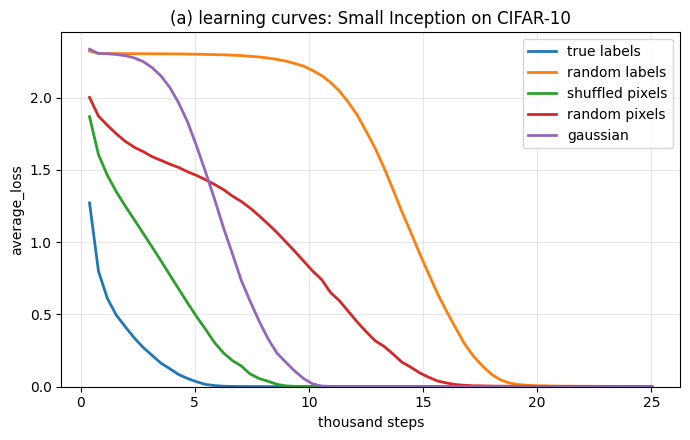

In [ ]:
labels = {
    "true_labels": "true labels", "random_labels": "random labels",
    "shuffled_labels": "shuffled labels", "shuffled_pixels": "shuffled pixels",
    "random_pixels": "random pixels", "gaussian": "gaussian",
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for cond in CONDITIONS:
    if cond in results:
        r = results[cond]
        ax.plot([s / 1000 for s in r["steps"]], r["avg_loss"], label=labels[cond], linewidth=2)
ax.set_xlabel("thousand steps")
ax.set_ylabel("average_loss")
ax.set_title("(a) learning curves: Small Inception on CIFAR-10")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
print(f"{'condition':18s} {'train acc':>10s} {'test acc':>10s} {'gap':>8s}")
for cond in CONDITIONS:
    if cond in results:
        r = results[cond]
        print(f"{labels[cond]:18s} {r['final_train_acc']:10.4f} {r['final_test_acc']:10.4f} "
              f"{r['final_train_acc'] - r['final_test_acc']:8.4f}")

condition           train acc   test acc      gap
true labels            1.0000     0.8706   0.1294
random labels          1.0000     0.1023   0.8977
shuffled pixels        1.0000     0.5230   0.4770
random pixels          1.0000     0.3618   0.6382
gaussian               1.0000     0.0990   0.9010


# Figures 1b and 1c: partially corrupted labels

> **Partially corrupted labels:** independently with probability p, the label of each image is
> corrupted as a uniform random class.

For each model and each corruption level p ∈ {0, 0.2, …, 1}, train until the network fits the
training set, then record:

- **(b) convergence slowdown:** steps to fit at level p, divided by steps to fit at p = 0
  for the same model. The y-axis is a ratio, so p = 0 is always exactly 1.
- **(c) generalization error:** test error (1 − test accuracy) at convergence. Training error
  is ≈ 0 by construction, so this *is* the generalization gap.

Three models, as in the paper: Small Inception (lr 0.1), small AlexNet and MLP 1x512 (lr 0.01).

**Convergence criterion.** The paper doesn't state one. Here a run has converged at the first
epoch whose training accuracy (measured online during that epoch) reaches `CONVERGE_ACC`.
I use 0.99 rather than 1.0 because Table 1 reports MLP 1x512 reaching only 99.34% on random
labels, so a 100% threshold would never trigger for it. Online accuracy slightly
*underestimates* end-of-epoch accuracy, since early batches see a less-trained model.

**Label noise vs. p.** A corrupted label is drawn uniformly from all 10 classes, so with
probability 1/10 it lands back on the true class. The fraction of actually-wrong labels is
0.9p, not p. At p = 1 the labels carry no information, so test error should approach 90%.

## Small AlexNet and MLPs

From Appendix A: *two (convolution 5x5 → max-pool 3x3 → local-response-normalization) modules
followed by two fully connected layers with 384 and 192 hidden units, and a 10-way linear layer.*
This matches TensorFlow's CIFAR-10 tutorial model, which uses 64 filters per conv layer and
stride-2 pooling.

**Translating LRN from TensorFlow to PyTorch.** TF computes
b = a / (k + α_TF · Σ a²)^β over `depth_radius` = 4 channels on each side, i.e. a window of 9.
PyTorch's `LocalResponseNorm(size, alpha)` computes b = a / (k + (alpha/size) · Σ a²)^β.
Matching the two denominators gives alpha = α_TF · size = (0.001/9) · 9 = 0.001, with size = 9,
β = 0.75 and k = 1.

The parameter counts below match Table 1 exactly: 1,387,786 for AlexNet and 1,209,866 for MLP 1x512.

In [10]:
class SmallAlexNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        lrn = lambda: nn.LocalResponseNorm(size=9, alpha=0.001, beta=0.75, k=1.0)
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 5, padding=2), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1), lrn(),          # 28 -> 14
            nn.Conv2d(64, 64, 5, padding=2), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1), lrn(),          # 14 -> 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 384), nn.ReLU(inplace=True),
            nn.Linear(384, 192), nn.ReLU(inplace=True),
            nn.Linear(192, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class MLP(nn.Module):
    """MLP with `depth` hidden layers of `width` units. MLP(1, 512) is 'MLP 1x512'."""

    def __init__(self, depth=1, width=512, in_dim=3 * 28 * 28, num_classes=10):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for _ in range(depth):
            layers += [nn.Linear(d, width), nn.ReLU(inplace=True)]
            d = width
        layers.append(nn.Linear(d, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


MODELS = {
    #  name           (constructor,             initial lr)
    "Inception": (SmallInception,           0.1),
    "AlexNet":   (SmallAlexNet,             0.01),
    "MLP 1x512": (lambda: MLP(1, 512),      0.01),
}

expected = {"Inception": 1_649_402, "AlexNet": 1_387_786, "MLP 1x512": 1_209_866}
for name, (fn, _) in MODELS.items():
    n_params = sum(p.numel() for p in fn().parameters())
    print(f"{name:10s} {n_params:>10,d}   paper: {expected[name]:>10,d}")
# With MATCH_TF_BATCHNORM = False, Inception has 1,712 extra params: one gamma per BN channel.

Inception   1,649,402   paper:  1,649,402
AlexNet     1,387,786   paper:  1,387,786
MLP 1x512   1,209,866   paper:  1,209,866


## Run the sweep

That's 3 models × 6 levels = 18 runs, which is a lot of Colab time. The MLP and AlexNet runs are
much cheaper than Inception, so a sensible order is to run those first and add Inception
afterwards. Results are saved after every run, and re-running the cell skips finished runs.

`MAX_EPOCHS` is a safety cap. By epoch 150 the learning rate is 0.1 · 0.95¹⁵⁰ ≈ 4.6 × 10⁻⁵
(or ten times smaller for lr 0.01), so a run that hasn't fit by then never will. It is recorded
as not converged.

In [12]:
P_LEVELS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
MODELS_TO_RUN = ["MLP 1x512", "AlexNet", "Inception"]
CONVERGE_ACC = 0.99
MAX_EPOCHS = 150

def make_label_noise(p, seed=SEED):
    """Clean images, training labels corrupted with probability p; test set untouched."""
    gen = torch.Generator().manual_seed(seed)
    Ytr = corrupt_labels(base_train_y, p, gen)
    return (per_image_whitening(base_train_x).to(device), Ytr.to(device),
            per_image_whitening(base_test_x).to(device), base_test_y.to(device))

# SWEEP_PATH = "sweep_results.json"
SWEEP_PATH = "/content/drive/MyDrive/rethinking_generalization_sweep.json"
try:
    with open(SWEEP_PATH) as f:
        sweep = json.load(f)
except FileNotFoundError:
    sweep = {}
print("already done:", list(sweep))

already done: ['MLP 1x512|p=0.0', 'AlexNet|p=0.0', 'Inception|p=0.0', 'MLP 1x512|p=0.2', 'AlexNet|p=0.2', 'Inception|p=0.2', 'MLP 1x512|p=0.4', 'AlexNet|p=0.4', 'Inception|p=0.4', 'MLP 1x512|p=0.6', 'AlexNet|p=0.6', 'Inception|p=0.6', 'MLP 1x512|p=0.8', 'AlexNet|p=0.8', 'Inception|p=0.8', 'MLP 1x512|p=1.0']


In [13]:
for p in P_LEVELS:
    data = make_label_noise(p)          # same corrupted labels for every model at this p
    for name in MODELS_TO_RUN:
        key = f"{name}|p={p}"
        if key in sweep:
            continue
        fn, lr = MODELS[name]
        sweep[key] = train_model(fn, data, lr, MAX_EPOCHS, converge_acc=CONVERGE_ACC, tag=key)
        sweep[key].update({"model": name, "p": p})
        with open(SWEEP_PATH, "w") as f:
            json.dump(sweep, f)
    del data

[AlexNet|p=1.0] epoch   0  lr 0.01000  avg_loss 2.3032  train_acc 0.0999  test_acc 0.0927  (7.7s)
[AlexNet|p=1.0] epoch   1  lr 0.00950  avg_loss 2.3025  train_acc 0.1040  test_acc 0.0905  (5.0s)
[AlexNet|p=1.0] epoch   2  lr 0.00903  avg_loss 2.3020  train_acc 0.1060  test_acc 0.0644  (5.0s)
[AlexNet|p=1.0] epoch   3  lr 0.00857  avg_loss 2.3013  train_acc 0.1075  test_acc 0.0680  (5.3s)
[AlexNet|p=1.0] epoch   4  lr 0.00815  avg_loss 2.3004  train_acc 0.1111  test_acc 0.0810  (5.1s)
[AlexNet|p=1.0] epoch   5  lr 0.00774  avg_loss 2.2994  train_acc 0.1138  test_acc 0.0917  (5.3s)
[AlexNet|p=1.0] epoch   6  lr 0.00735  avg_loss 2.2979  train_acc 0.1199  test_acc 0.1019  (5.1s)
[AlexNet|p=1.0] epoch   7  lr 0.00698  avg_loss 2.2957  train_acc 0.1212  test_acc 0.0990  (5.1s)
[AlexNet|p=1.0] epoch   8  lr 0.00663  avg_loss 2.2932  train_acc 0.1276  test_acc 0.1071  (5.2s)
[AlexNet|p=1.0] epoch   9  lr 0.00630  avg_loss 2.2897  train_acc 0.1320  test_acc 0.0971  (5.2s)
[AlexNet|p=1.0] epoc

## Results: Figures 1b and 1c

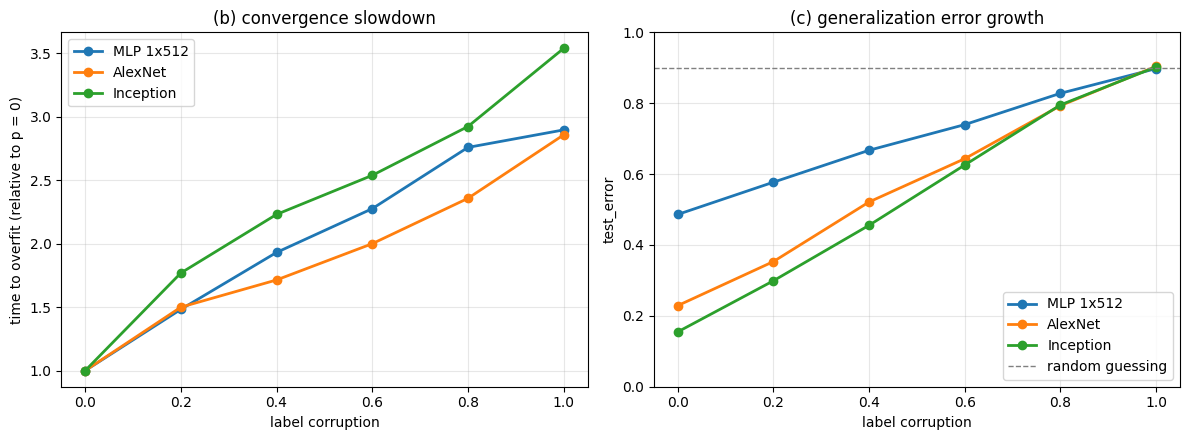

In [14]:
fig, (ax_b, ax_c) = plt.subplots(1, 2, figsize=(12, 4.5))

for name in MODELS_TO_RUN:
    base = sweep.get(f"{name}|p=0.0")
    if base is None or base["converged_step"] is None:
        print(f"{name}: no converged p=0 run yet, skipping")
        continue
    ps, slowdown, test_err = [], [], []
    for p in P_LEVELS:
        r = sweep.get(f"{name}|p={p}")
        if r is None:
            continue
        if r["converged_step"] is None:
            print(f"{name} p={p}: did not reach {CONVERGE_ACC} within {MAX_EPOCHS} epochs")
            continue
        ps.append(p)
        slowdown.append(r["converged_step"] / base["converged_step"])
        test_err.append(1 - r["final_test_acc"])
    ax_b.plot(ps, slowdown, "o-", label=name, linewidth=2)
    ax_c.plot(ps, test_err, "o-", label=name, linewidth=2)

ax_b.set(xlabel="label corruption", ylabel="time to overfit (relative to p = 0)",
         title="(b) convergence slowdown")
ax_c.set(xlabel="label corruption", ylabel="test_error", ylim=(0, 1),
         title="(c) generalization error growth")
ax_c.axhline(0.9, color="gray", linestyle="--", linewidth=1, label="random guessing")
for ax in (ax_b, ax_c):
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [15]:
print(f"{'run':20s} {'epochs':>7s} {'train acc':>10s} {'test err':>9s}")
for key, r in sweep.items():
    ep = r["converged_epoch"] if r["converged_epoch"] is not None else f">{MAX_EPOCHS}"
    print(f"{key:20s} {str(ep):>7s} {r['final_train_acc']:10.4f} {1 - r['final_test_acc']:9.4f}")

run                   epochs  train acc  test err
MLP 1x512|p=0.0           29     0.9948    0.4861
AlexNet|p=0.0             14     0.9985    0.2288
Inception|p=0.0           13     0.9895    0.1547
MLP 1x512|p=0.2           43     0.9926    0.5771
AlexNet|p=0.2             21     0.9964    0.3531
Inception|p=0.2           23     0.9956    0.2989
MLP 1x512|p=0.4           56     0.9917    0.6672
AlexNet|p=0.4             24     0.9941    0.5213
Inception|p=0.4           29     0.9986    0.4555
MLP 1x512|p=0.6           66     0.9917    0.7396
AlexNet|p=0.6             28     0.9968    0.6434
Inception|p=0.6           33     0.9985    0.6256
MLP 1x512|p=0.8           80     0.9910    0.8279
AlexNet|p=0.8             33     0.9971    0.7930
Inception|p=0.8           38     0.9947    0.7951
MLP 1x512|p=1.0           84     0.9908    0.8976
AlexNet|p=1.0             40     0.9938    0.9039
Inception|p=1.0           46     0.9993    0.9024


Notes
- This is a great question, because the name is misleading. In deep learning, “SGD” almost always means mini-batch SGD. The single-example version from Lecture 2 is the special case where the batch size is 1.